# Практическая работа: граф друзей VK
**Предмет:** Интеллектуальные системы и технологии  
**Автор:** Черномырдин Михаил Алексеевич, БСМО‑12‑26.

Цель: построить неориентированный граф участников группы, их друзей и друзей друзей; сравнить участников по посредничеству, близости и собственному вектору.

Глубина сбора — два перехода от участников, как на выданном слайде задания. Списки запрашивались у участников (уровень 0) и их непосредственных друзей (уровень 1). У вершин второго круга списки не запрашивались. Поэтому это граф **наблюдаемых связей**, не полный индуцированный подграф второго круга.

Обращений к VK здесь нет. Ключ доступа и папка браузера не нужны. SQLite содержит уже извлечённые списки; сначала они экспортируются в CSV, затем начинается анализ.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%pip -q install "networkx==3.5" pandas scipy matplotlib tqdm

In [ ]:
from pathlib import Path
import sqlite3, json, csv, gzip, random, time, shutil
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse.linalg import eigsh
from tqdm.auto import tqdm
from IPython.display import display
from google.colab import files
uploaded = files.upload()
DB = Path('friends_web_api_cache.sqlite3')
COVERAGE = Path('coverage.csv')
assert DB.exists() and COVERAGE.exists(), 'Загрузите оба файла: SQLite и coverage.csv'
OUT = Path('vk_analysis_results')
OUT.mkdir(exist_ok=True)

Saving centrality.csv to centrality.csv
Saving coverage.csv to coverage.csv
Saving friends_web_api_cache.sqlite3 to friends_web_api_cache.sqlite3


## 1. Восстановление и проверка данных
Одна строка SQLite — список друзей одного профиля и статус запроса. Неудачный запрос не означает отсутствие друзей. Вершины с недоступными списками могут иметь рёбра, обнаруженные из списков других людей. Повторные рёбра и петли исключаются.

In [ ]:
coverage = pd.read_csv(COVERAGE, dtype=str).fillna('')
assert {'profile','vk_id','depth','status','friends_returned'} <= set(coverage.columns)
valid = coverage[coverage.vk_id.str.fullmatch(r'[0-9]+')].copy()
valid['vk_id'] = valid.vk_id.astype('int64')
valid['depth'] = valid.depth.astype(int)
assert set(valid.depth) <= {0, 1}, 'Неожиданные уровни в coverage.csv'
members = valid[valid.depth == 0].drop_duplicates('vk_id').copy()
assert len(members), 'Нет распознанных участников группы'
member_ids = members.vk_id.tolist()
labels = dict(zip(members.vk_id, members.profile.str.rsplit('/', n=1).str[-1]))
G = nx.Graph()
G.add_nodes_from(member_ids)
with sqlite3.connect(DB.resolve().as_uri() + '?mode=ro', uri=True) as conn:
    records = {int(u): (s, json.loads(ids)) for u,s,ids in conn.execute('SELECT user_id,status,ids FROM friends')}
for row in valid.itertuples():
    assert row.vk_id in records, f'В кэше нет id{row.vk_id}'
    status, ids = records[row.vk_id]
    assert isinstance(ids, list) and all(type(v) is int and v > 0 for v in ids)
    assert status == row.status, f'Статус id{row.vk_id} отличается: файлы из разных запусков?'
    if row.friends_returned:
        assert len(ids) == int(row.friends_returned), f'Не совпало число друзей id{row.vk_id}'
    G.add_node(row.vk_id)
    G.add_edges_from((row.vk_id,v) for v in ids if v != row.vk_id)
N, M = G.number_of_nodes(), G.number_of_edges()
print(f'Участников: {len(member_ids)}. Вершин: {N:,}. Рёбер: {M:,}.')
display(pd.crosstab(coverage.depth, coverage.status))
print('Нераспознанных участников:', len(coverage[coverage.status == 'unresolved']))

Участников: 17. Вершин: 481,350. Рёбер: 593,844.


status,ok,vk_error_18,vk_error_30
depth,,,
0,13,0,4
1,1447,46,463


Нераспознанных участников: 0


In [ ]:
# Экспорт ДО вычисления центральностей. G содержит все наблюдаемые связи.
with gzip.open(OUT / 'edges.csv.gz', 'wt', encoding='utf-8', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['source', 'target'])
    writer.writerows(G.edges())
first = set(valid.loc[valid.depth == 1, 'vk_id'])
member_set = set(member_ids)
status_map = dict(zip(valid.vk_id, valid.status))
with gzip.open(OUT / 'nodes.csv.gz', 'wt', encoding='utf-8', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['vk_id','depth','is_member','friends_status'])
    writer.writerows((u, 0 if u in member_set else 1 if u in first else 2,
                      int(u in member_set), status_map.get(u,'not_requested')) for u in G)
coverage.to_csv(OUT / 'coverage.csv', index=False, encoding='utf-8-sig')
members.to_csv(OUT / 'members.csv', index=False, encoding='utf-8-sig')
print('Исходные данные экспортированы: edges.csv.gz, nodes.csv.gz, members.csv, coverage.csv')

Исходные данные экспортированы: edges.csv.gz, nodes.csv.gz, members.csv, coverage.csv


## 2. Метрики и их смысл
* **Посредничество:** доля кратчайших путей между другими вершинами, проходящих через данную. Нормировка для неориентированного графа: $2/((N-1)(N-2))$.
* **Близость из лекции:** $1/\sum_j d(i,j)$. В таблице `closeness_lecture_component` сумма взята по достижимым вершинам. Для сравнения разных компонент также вычисляется `closeness_wf`: $(r-1)/(N-1)\cdot(r-1)/\sum_j d(i,j)$, где $r$ — размер компоненты.
* **Собственный вектор:** $Ax=\lambda_{max}x$. Вычисляется на каждой связной компоненте, норма вектора равна 1. Значения из разных компонент нельзя напрямую считать единым рейтингом. Для изолированных вершин значение оставлено пустым.

Метрики используют весь собранный граф; итоговая таблица содержит только участников группы. Сведения об ошибках сбора сохраняются рядом с оценками.

**Посредничество по умолчанию приближённое:** 64 случайных источника, seed=42. Это сокращает работу по сравнению с 512 источниками, но точность ниже; близкие результаты нельзя уверенно ранжировать. `SAMPLES=0` включает точный, потенциально очень долгий расчёт. Эти настройки относятся только к анализу, повторного сбора VK нет.

In [ ]:
SAMPLES = 64  # 0 = точный расчёт; 512 = более дорогая выборочная оценка
SEED = 42
assert SAMPLES >= 0
k = min(SAMPLES, N) if SAMPLES else None
if k == N:
    k = None
print(f'Посредничество: {"точно" if k is None else str(k) + " источника"}. Эта ячейка может выполняться долго.', flush=True)
t0 = time.perf_counter()
between = nx.betweenness_centrality(G, k=k, normalized=True, seed=SEED)
print(f'Посредничество готово за {(time.perf_counter()-t0)/60:.1f} мин')

Посредничество: 64 источника. Эта ячейка может выполняться долго.
Посредничество готово за 2.8 мин


In [ ]:
component_id, component_size, eigen = {}, {}, {}
for cid, component in enumerate(nx.connected_components(G)):
    targets = member_set.intersection(component)
    if not targets:
        continue
    for u in targets:
        component_id[u], component_size[u] = cid, len(component)
    if len(component) == 1:
        eigen.update({u: np.nan for u in targets})
        continue
    nodes = sorted(component)
    if len(nodes) == 2:
        vector = np.ones(2) / np.sqrt(2)
    else:
        A = nx.to_scipy_sparse_array(G.subgraph(nodes), nodelist=nodes, dtype=float, format='csr')
        values, vectors = eigsh(A, k=1, which='LA', tol=1e-8, v0=np.ones(len(nodes)))
        vector = np.abs(vectors[:,0])
        vector /= np.linalg.norm(vector)
        residual = np.linalg.norm(A @ vector - values[0] * vector)
        assert residual <= 1e-5 * max(1, abs(values[0])), 'Не сошёлся собственный вектор'
    eigen.update((u, float(vector[i])) for i,u in enumerate(nodes) if u in targets)
rows = []
for u in tqdm(member_ids, desc='Близость участников'):
    distances = nx.single_source_shortest_path_length(G, u)
    total, r = sum(distances.values()), len(distances)
    observed = G.degree(u) > 0 or status_map[u] == 'ok'
    rows.append(dict(vk_id=u, profile=labels[u], friends_status=status_map[u],
        degree=G.degree(u), component=component_id[u], component_size=r,
        betweenness=between[u] if observed else np.nan,
        closeness_lecture_component=1/total if total else np.nan,
        closeness_wf=((r-1)**2/((N-1)*total) if total and N>1 else 0) if observed else np.nan,
        eigenvector_component=eigen[u]))
result = pd.DataFrame(rows).sort_values('betweenness', ascending=False)
result.to_csv(OUT / 'centrality.csv', index=False, encoding='utf-8-sig')
display(result)

Близость участников:   0%|          | 0/17 [00:00<?, ?it/s]

,vk_id,profile,friends_status,degree,component,component_size,betweenness,closeness_lecture_component,closeness_wf,eigenvector_component
0,357111839,andrew.kirillov,ok,256,0,481350,6.808610e-02,5.803585e-07,0.279355,0.002448
10,139159408,id139159408,ok,275,0,481350,6.402134e-02,5.659684e-07,0.272428,0.001394
6,465105120,medvediano,ok,181,0,481350,6.301370e-02,5.888207e-07,0.283428,0.001588
4,299547783,dimitr101,ok,272,0,481350,4.207876e-02,6.105360e-07,0.293881,0.001076
2,365680993,y.doyneko,ok,288,0,481350,3.634127e-02,6.002437e-07,0.288927,0.000646
3,223966628,saulinivan,ok,154,0,481350,3.419825e-02,5.792340e-07,0.278814,0.000622
8,473310225,0pupok00,ok,177,0,481350,2.489675e-02,5.722598e-07,0.275457,0.001320
15,322111274,foreverlostintears,ok,157,0,481350,2.314624e-02,5.884201e-07,0.283235,0.000491
14,143873880,asstynj,ok,65,0,481350,1.239730e-02,5.518928e-07,0.265653,0.014033
5,288851914,ku_ku_riz,ok,105,0,481350,7.285461e-03,4.843483e-07,0.233141,0.000016


## 3. Визуализация
Первый рисунок показывает связи непосредственно между участниками. Второй — все наблюдаемые непосредственные друзья участников. Это **фрагменты для читаемости**, не граф, на котором считались метрики. Полный список рёбер сохранён в `edges.csv.gz`.

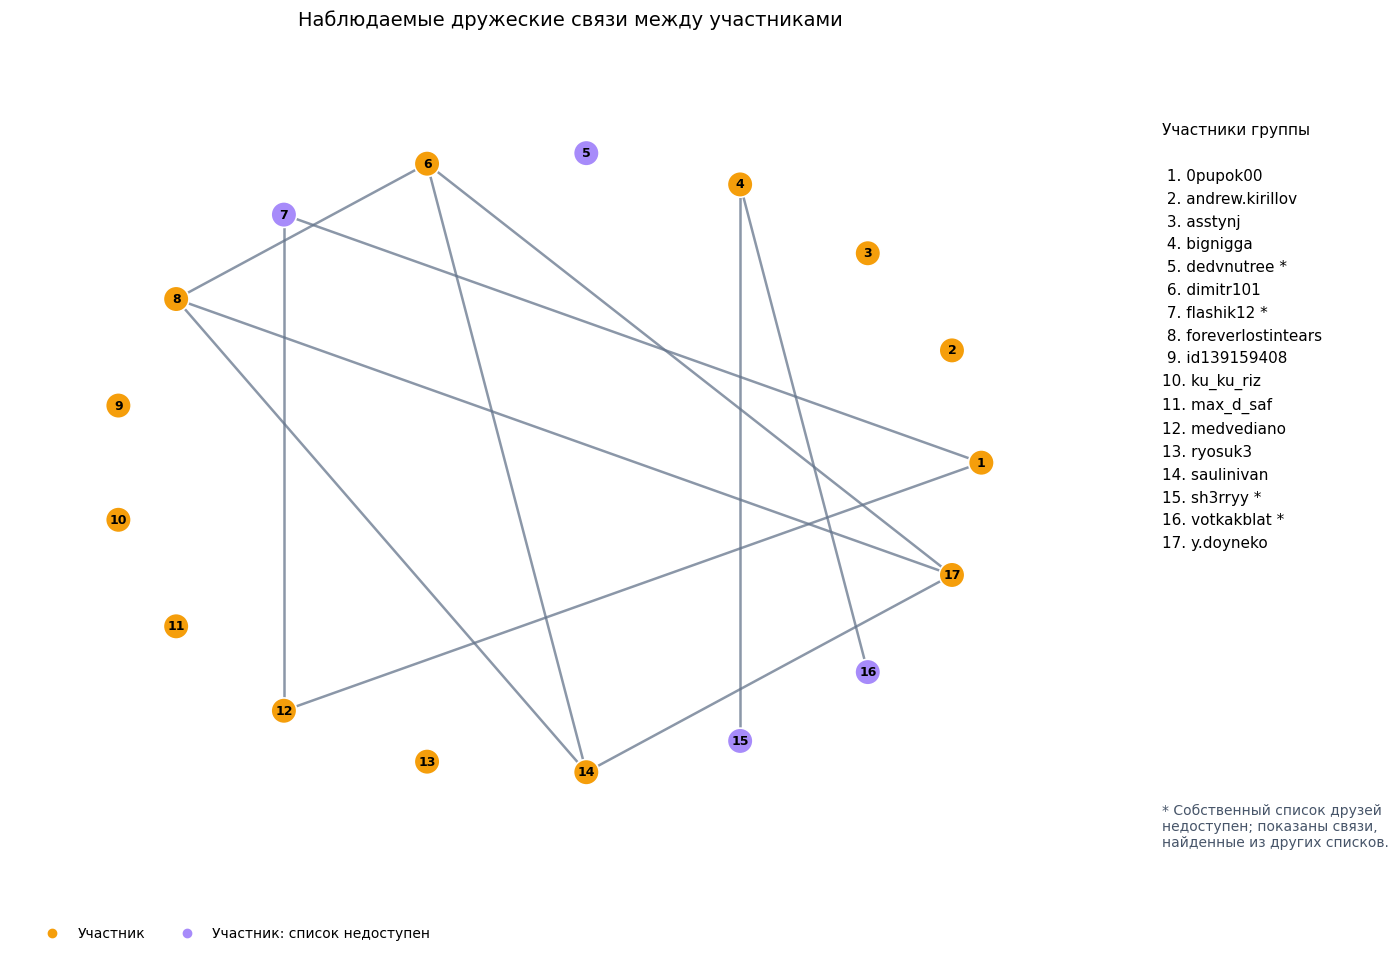

Раскладка графа: 1,973 вершин, 14,475 рёбер. Подождите.


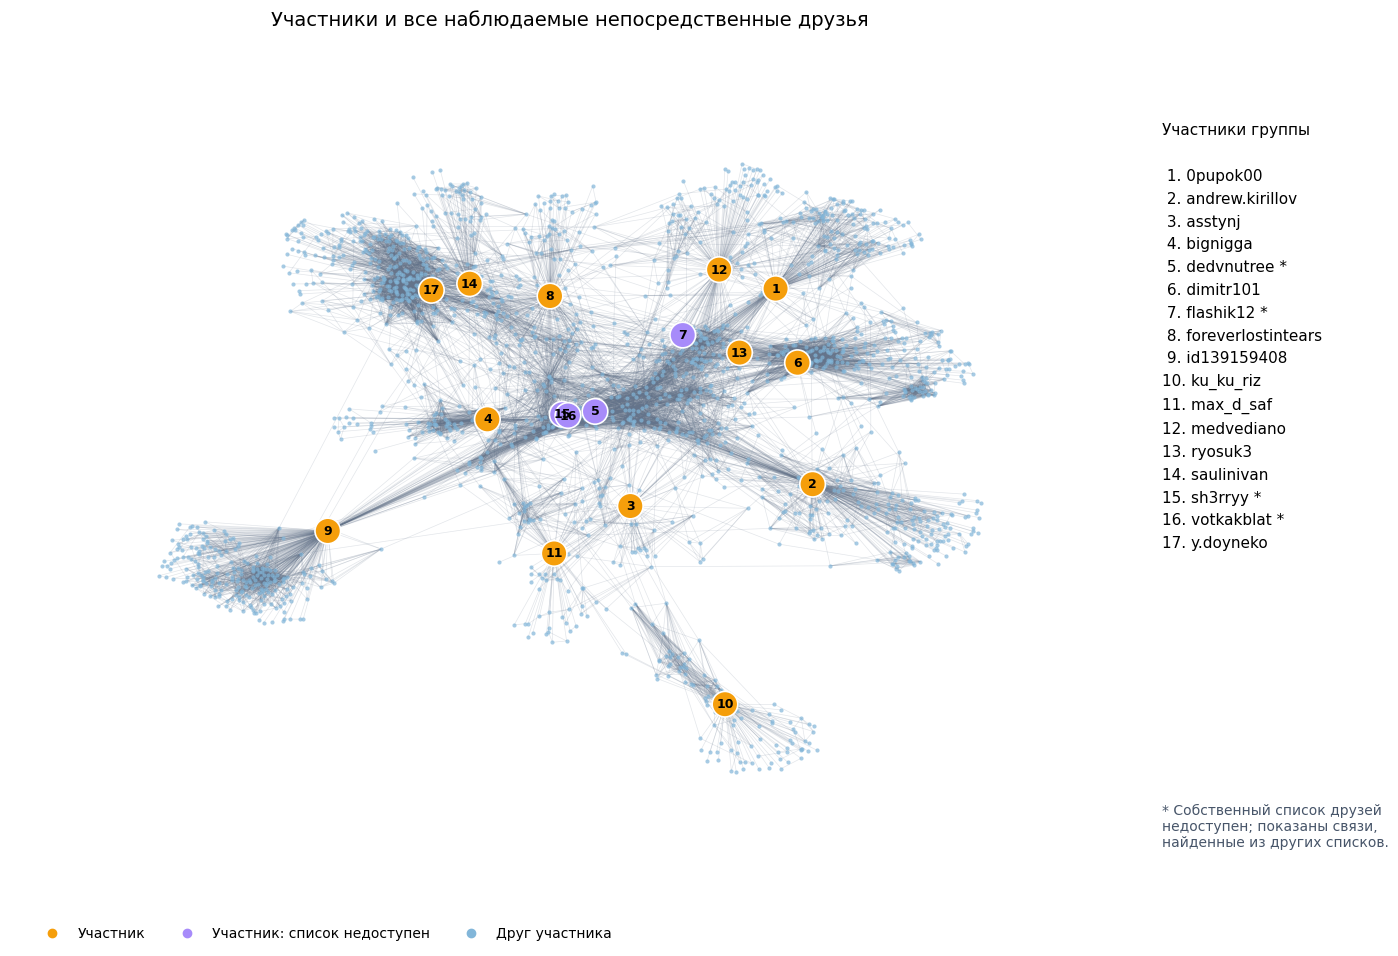

Готово. Изменены только рисунки. Центральности по-прежнему рассчитаны на полном графе.


In [ ]:
from matplotlib.lines import Line2D

# Номера участников и обозначение недоступных списков друзей.
ordered = sorted(member_ids, key=lambda u: labels[u].lower())
numbers = {u: str(i + 1) for i, u in enumerate(ordered)}
unavailable = {u for u in ordered if status_map.get(u) != "ok"}

legend_text = "\n".join(
    f"{numbers[u]:>2}. {labels[u]}"
    + (" *" if u in unavailable else "")
    for u in ordered
)

def plot_network(H, pos, title, filename, show_friends=False):
    fig, ax = plt.subplots(figsize=(16, 10))
    fig.subplots_adjust(left=0.03, right=0.73, top=0.91, bottom=0.08)

    nx.draw_networkx_edges(
        H, pos, ax=ax,
        edge_color="#64748b",
        alpha=0.18 if show_friends else 0.75,
        width=0.5 if show_friends else 1.8,
    )

    friends = [u for u in H if u not in member_set]
    if friends:
        nx.draw_networkx_nodes(
            H, pos, ax=ax, nodelist=friends,
            node_size=9, node_color="#82b6d9",
            alpha=0.7, linewidths=0,
        )

    nx.draw_networkx_nodes(
        H, pos, ax=ax, nodelist=ordered,
        node_size=340,
        node_color=[
            "#a78bfa" if u in unavailable else "#f59e0b"
            for u in ordered
        ],
        edgecolors="white", linewidths=1.2,
    )
    nx.draw_networkx_labels(
        H, pos, ax=ax, labels=numbers,
        font_size=9, font_weight="bold",
    )

    fig.text(
        0.75, 0.84, "Участники группы\n\n" + legend_text,
        va="top", fontsize=11, linespacing=1.65,
    )
    fig.text(
        0.75, 0.16,
        "* Собственный список друзей\n"
        "недоступен; показаны связи,\n"
        "найденные из других списков.",
        va="top", fontsize=10, color="#475569",
    )

    ax.set_title(title, fontsize=14, pad=20)
    ax.margins(0.12)
    ax.set_axis_off()

    handles = [
        Line2D([], [], marker="o", linestyle="",
               color="#f59e0b", label="Участник"),
        Line2D([], [], marker="o", linestyle="",
               color="#a78bfa", label="Участник: список недоступен"),
    ]
    if show_friends:
        handles.append(
            Line2D([], [], marker="o", linestyle="",
                   color="#82b6d9", label="Друг участника")
        )
    fig.legend(
        handles=handles, loc="lower left",
        bbox_to_anchor=(0.04, 0.01), ncol=len(handles),
        frameon=False,
    )

    fig.savefig(OUT / filename, dpi=180, bbox_inches="tight")
    plt.show()


# 1. Только участники: круговая раскладка.
H_members = G.subgraph(ordered).copy()
plot_network(
    H_members,
    nx.circular_layout(ordered),
    "Наблюдаемые дружеские связи между участниками",
    "members_graph.png",
)

# 2. Участники и ВСЕ найденные непосредственные друзья.
first_circle = set(ordered)
for u in ordered:
    first_circle.update(G.neighbors(u))

H_friends = G.subgraph(first_circle).copy()

print(
    f"Раскладка графа: {H_friends.number_of_nodes():,} вершин, "
    f"{H_friends.number_of_edges():,} рёбер. Подождите.",
    flush=True,
)

positions = nx.spring_layout(
    H_friends,
    seed=42,
    k=0.12,
    iterations=80,
    weight=None,
)

plot_network(
    H_friends,
    positions,
    "Участники и все наблюдаемые непосредственные друзья",
    "graph_fragment.png",
    show_friends=True,
)

print(
    "Готово. Изменены только рисунки. "
    "Центральности по-прежнему рассчитаны на полном графе."
)

In [ ]:
summary = dict(vertices=N, edges=M, components=nx.number_connected_components(G),
    members_resolved=len(member_ids), members_unresolved=int((coverage.status=='unresolved').sum()),
    betweenness_method='exact' if k is None else 'sampled', samples=k, seed=SEED,
    coverage_statuses=coverage.status.value_counts().to_dict(), networkx_version=nx.__version__)
(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
lines = [f'Построен граф из {N} вершин и {M} наблюдаемых связей.',
         f'Число компонент связности: {summary["components"]}.',
         f'Посредничество: {"точный расчёт" if k is None else "приближённая оценка, источников " + str(k)}.']
for metric, title in [('betweenness','Посредничество'),('closeness_wf','Близость WF')]:
    col = result.dropna(subset=[metric])
    if len(col):
        leaders = col.loc[col[metric] == col[metric].max(), 'profile'].tolist()
        lines.append(title + ': максимальное значение у ' + ', '.join(leaders) + '.')
for cid, frame in result.groupby('component'):
    col = frame.dropna(subset=['eigenvector_component'])
    if len(col):
        leaders = col.loc[col.eigenvector_component == col.eigenvector_component.max(), 'profile'].tolist()
        lines.append(f'Собственный вектор, компонента {cid}: максимум среди участников у ' + ', '.join(leaders) + '.')
lines += ['Результаты характеризуют доступный снимок данных. Недоступные списки и не обследованные связи между вершинами второго круга могут менять оценки.',
          'При выборочном посредничестве порядок близких значений может зависеть от выборки.']
text = '\n'.join(lines)
print(text)
(OUT / 'conclusions.txt').write_text(text, encoding='utf-8')

Построен граф из 481350 вершин и 593844 наблюдаемых связей.
Число компонент связности: 1.
Посредничество: приближённая оценка, источников 64.
Посредничество: максимальное значение у andrew.kirillov.
Близость WF: максимальное значение у dimitr101.
Собственный вектор, компонента 0: максимум среди участников у asstynj.
Результаты характеризуют доступный снимок данных. Недоступные списки и не обследованные связи между вершинами второго круга могут менять оценки.
При выборочном посредничестве порядок близких значений может зависеть от выборки.


544